# Análisis exploratorio: Telco Customer Churn

Responde 5 preguntas de negocio con pandas. Ejecuta con **Kernel → Restart & Run All**.
Requiere el CSV en `data/` (ver README).

In [1]:
import sys
sys.path.append("..")  # para importar src/ desde notebooks/

import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_clean

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = load_clean(DATA_PATH)
print(df.shape)
df.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Limpieza
`TotalCharges` viene como texto y trae 11 filas vacías (clientes con `tenure = 0`).
`load_clean` las convierte a número y las rellena con 0. Comprobación:

In [2]:
print("Tipo de TotalCharges:", df["TotalCharges"].dtype)
print("Nulos en TotalCharges:", df["TotalCharges"].isna().sum())
print("Clientes con tenure = 0:", (df["tenure"] == 0).sum())

Tipo de TotalCharges: float64
Nulos en TotalCharges: 0
Clientes con tenure = 0: 11


## 1. ¿Cuál es la tasa de churn global?

In [3]:
overall = df["Churn"].mean()
print(f"Tasa de churn global: {overall:.2%}  ({df['Churn'].sum()} de {len(df)} clientes)")

Tasa de churn global: 26.54%  (1869 de 7043 clientes)


## 2. ¿Cómo cambia el churn según el tipo de contrato?

,clientes,tasa_churn
Contract,,
Month-to-month,3875,0.4271
One year,1473,0.1127
Two year,1695,0.0283


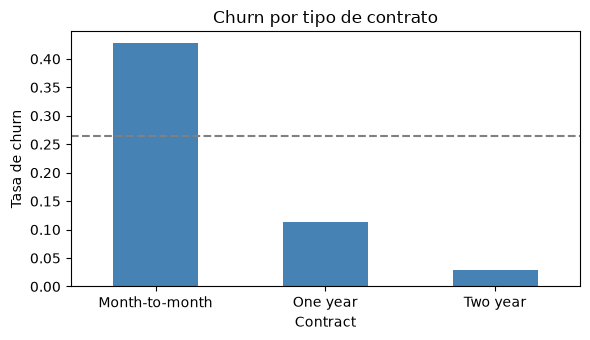

In [4]:
by_contract = df.groupby("Contract")["Churn"].agg(clientes="count", tasa_churn="mean").sort_values("tasa_churn", ascending=False)
by_contract["tasa_churn"] = by_contract["tasa_churn"].round(4)
display(by_contract)

ax = by_contract["tasa_churn"].plot.bar(rot=0, figsize=(6, 3.5), color="steelblue")
ax.axhline(overall, ls="--", color="gray")
ax.set_ylabel("Tasa de churn")
ax.set_title("Churn por tipo de contrato")
plt.tight_layout()
plt.show()

## 3. ¿Cómo cambia el churn según la antigüedad?

In [5]:
buckets = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
by_tenure = df.groupby(buckets, observed=True)["Churn"].agg(clientes="count", tasa_churn="mean")
by_tenure["tasa_churn"] = by_tenure["tasa_churn"].round(4)
by_tenure

,clientes,tasa_churn
tenure,,
0-6,1481,0.5294
7-12,705,0.3589
13-24,1024,0.2871
25-48,1594,0.2039
49-72,2239,0.0951


## 4. ¿Qué tipo de internet y qué método de pago tienen más churn?

In [6]:
for col in ["InternetService", "PaymentMethod"]:
    t = df.groupby(col)["Churn"].agg(clientes="count", tasa_churn="mean").sort_values("tasa_churn", ascending=False)
    t["tasa_churn"] = t["tasa_churn"].round(4)
    display(t)

,clientes,tasa_churn
InternetService,,
Fiber optic,3096,0.4189
DSL,2421,0.1896
No,1526,0.0740


,clientes,tasa_churn
PaymentMethod,,
Electronic check,2365,0.4529
Mailed check,1612,0.1911
Bank transfer (automatic),1544,0.1671
Credit card (automatic),1522,0.1524


## 5. ¿Pagan más los clientes que se van?

In [7]:
charges = df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2)
charges.index = ["Se quedan (0)", "Se van (1)"]
charges

,mean,median
Se quedan (0),61.27,64.43
Se van (1),74.44,79.65


## Conclusiones

Sobre una base de **7,043 clientes** con una tasa de churn global de **26.54 %** (1,869 bajas), el análisis identifica cuatro patrones principales de abandono:

- **Tipo de contrato:** Los contratos mes a mes (`Month-to-month`) presentan una tasa de churn de **42.71 %** (3,875 clientes), frente a **11.27 %** en contratos de un año y **2.83 %** en contratos de dos años (un riesgo 15 veces mayor). Este segmento concentra casi 9 de cada 10 bajas totales.
- **Antigüedad (`tenure`):** Más de la mitad de los clientes nuevos de **0 a 6 meses** abandona el servicio (**52.94 %** de 1,481 clientes). La tasa cae de forma continua conforme aumenta la permanencia, hasta llegar a **9.51 %** en el grupo de **49 a 72 meses** (2,239 clientes).
- **Servicio de internet y método de pago:** El abandono es considerablemente mayor entre usuarios de **fibra óptica** (**41.89 %**, frente a **18.96 %** en DSL y **7.40 %** sin internet) y en quienes pagan con **cheque electrónico** (**45.29 %**, frente a **15.24 %–19.11 %** en los demás métodos).
- **Cargo mensual (`MonthlyCharges`):** Los clientes que cancelan pagan una mediana de **$79.65/mes** (media de **$74.44**), frente a **$64.43/mes** (media de **$61.27**) en quienes permanecen; es decir, una diferencia de **$15.22** mensuales en la mediana.